### Organize it into these sections:
1. Imports and data loading
2. Initial dataset inspection
3. Data cleaning
4. Missing values analysis
5. Area standardization
6. Duplicate detection
7. Data-quality EDA
8. Export cleaned dataset

Import libraries

In [1]:
import pandas as pd
import numpy as np
import json
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 100)

print("Libraries imported successfully!")

Libraries imported successfully!


Step 4 — Load and combine the JSON files

In [2]:
def load_json(filename):

    with open(filename, 'r', encoding='utf-8') as file:
        data = json.load(file)

    # Handle different JSON structures
    if isinstance(data, list):
        return pd.DataFrame(data)

    elif isinstance(data, dict):
        if 'data' in data and isinstance(data['data'], list):
            return pd.DataFrame(data['data'])

        return pd.DataFrame([data])

    else:
        raise ValueError(f"Unexpected JSON structure in {filename}")


# Load Fifth Settlement
df_fifth = load_json('fifth-settlement-discovery.json')

# Load Rehab / First Settlement
df_rehab = load_json('Rehab-discovery.json')


# Combine both datasets
df_places = pd.concat(
    [df_fifth, df_rehab],
    ignore_index=True
)

print("Dataset loaded successfully!")
print("Total places:", len(df_places))

Dataset loaded successfully!
Total places: 684


In [3]:
df_places

,title,subTitle,description,ownerDescription,price,categoryName,address,neighborhood,street,city,postalCode,state,countryCode,phone,phoneUnformatted,claimThisBusiness,location,locatedIn,floor,plusCode,menu,servicesLink,totalScore,permanentlyClosed,temporarilyClosed,placeId,categories,fid,cid,reviewsCount,reviewsDistribution,imagesCount,imageCategories,scrapedAt,reserveTableUrl,googleFoodUrl,hotelStars,hotelDescription,checkInDate,checkOutDate,hotelAds,popularTimesLiveText,popularTimesLivePercent,popularTimesHistogram,openingHours,wasOpenAtScrapeTime,peopleAlsoSearch,placesTags,reviewsTags,gasPrices,url,searchPageUrl,searchString,language,rank,isAdvertisement,imageUrl,kgmid,businessProfileId,additionalInfo,questionsAndAnswers,webResults,tableReservationLinks,tableReservationProviders,bookingLinks,restaurantData,ownerUpdates,imageUrls,reviews,leadsEnrichment,updatesFromCustomers,website,additionalOpeningHours
0,Yorki Pizza,None,None,None,None,Pizza restaurant,"2C28+3PW Zeina Mall, شارع ١٦، New Cairo 1, Cairo Governorate 11865, Egypt",None,"2C28+3PW Zeina Mall, شارع ١٦",New Cairo 1,11865,Cairo Governorate,EG,+20 15 59816169,+201559816169,True,"{'lat': 30.0002356, 'lng': 31.4168186}",None,None,None,None,None,3.3,False,False,ChIJe86CavU9WBQRsTtU5ukMwyY,[Pizza restaurant],0x14583df56a82ce7b:0x26c30ce9e6543bb1,2793090392631032753,3.0,"{'oneStar': 1, 'twoStar': 0, 'threeStar': 0, 'fourStar': 1, 'fiveStar': 1}",0,[By owner],2026-10-25T17:21:06.686Z,None,None,None,None,None,None,[],None,NaN,{},"[{'day': 'Monday', 'hours': '2 PM to 12 AM'}, {'day': 'Tuesday', 'hours': '2 PM to 12 AM'}, {'da...",True,"[{'category': 'People also search for', 'title': 'UNO pizza', 'reviewsCount': 18, 'totalScore': ...",[],[],[],https://www.google.com/maps/search/?api=1&query=Yorki%20Pizza&query_place_id=ChIJe86CavU9WBQRsTt...,"https://www.google.com/maps/search/%D8%A8%D9%8A%D8%AA%D8%B2%D8%A7/@29.99982456925998,31.42053860...",بيتزا,en,13,False,None,/g/11nh41nw2r,None,"{'Service options': [{'Delivery': True}, {'Takeout': True}, {'Dine-in': True}], 'Popular for': [...",[],[],[],[],[],{'tableReservationProvider': None},[],[],[],[],NaN,NaN,NaN
1,pizza 88,None,None,None,E£200–400,Pizza restaurant,"2C3F+HCJ بجوار شورما حلب, New Cairo 1, Cairo Governorate 4723113, Egypt",None,2C3F+HCJ بجوار شورما حلب,New Cairo 1,None,Cairo Governorate,EG,,,True,"{'lat': 30.0039749, 'lng': 31.4235106}",Twin Plaza mall - new Cairo,None,None,None,None,3.5,False,False,ChIJ5f22KAA9WBQR0kwXXlcbW4U,[Pizza restaurant],0x14583d0028b6fde5:0x855b1b575e174cd2,9609304291979775186,27.0,"{'oneStar': 8, 'twoStar': 1, 'threeStar': 2, 'fourStar': 2, 'fiveStar': 14}",0,"[All, Food & drink, Pizza, By owner]",2026-10-25T17:21:08.020Z,None,None,None,None,None,None,[],None,NaN,{},[],None,"[{'category': 'People also search for', 'title': 'Pizza '88 - Mobil Gas Station Concord', 'revie...",[],"[{'title': 'chicks', 'count': 2}, {'title': 'literally', 'count': 2}]",[],https://www.google.com/maps/search/?api=1&query=pizza%2088&query_place_id=ChIJ5f22KAA9WBQR0kwXXl...,"https://www.google.com/maps/search/%D8%A8%D9%8A%D8%AA%D8%B2%D8%A7/@29.99982456925998,31.42053860...",بيتزا,en,12,False,https://gz0.googleusercontent.com/grass-proxy/AIM7gW3FBAxqCGHJtBEN1F_n0pX5qpyF24TUHyaSl_56wYQOtU...,/g/11xrzr4p2w,None,"{'Service options': [{'Takeout': True}, {'Dine-in': True}], 'Popular for': [{'Lunch': True}, {'D...",[],[],[],[],[],{'tableReservationProvider': None},[],[],[],[],"{'text': None, 'language': None, 'postDate': '8 months ago', 'postedBy': {'name': 'Elsayed Elbou...",NaN,NaN
2,Pizza Bob AlTagamoaa,None,None,"Pizza Smells Sea, بيتزا سي فود بريحة البحر","E£200–1,200",Pizza restaurant,"امام حي ١, Street 15, New Cairo 1, Cairo Governorate 11856, Egypt",None,"امام حي ١, Street 15",New Cairo 1,11856,Cairo Governorate,EG,+20 12 88882764,+201288882764,False,"{'lat': 30.0060522, 'lng': 31.4249543}",None,None,"2C4F+CX New Cairo 1, Egypt",https://linktr.ee/pizza.bob,None,4.0,False,False,ChIJ71zoEgA9WBQRiMecb_IYk-o,[Pizza re

In [10]:
df_fifth['source_file'] = 'fifth-settlement-discovery.json'
df_rehab['source_file'] = 'Rehab-discovery.json'

df_places_raw = pd.concat(
    [df_fifth, df_rehab],
    ignore_index=True
)

In [6]:
df_places.head()

,title,subTitle,description,ownerDescription,price,categoryName,address,neighborhood,street,city,postalCode,state,countryCode,phone,phoneUnformatted,claimThisBusiness,location,locatedIn,floor,plusCode,menu,servicesLink,totalScore,permanentlyClosed,temporarilyClosed,placeId,categories,fid,cid,reviewsCount,reviewsDistribution,imagesCount,imageCategories,scrapedAt,reserveTableUrl,googleFoodUrl,hotelStars,hotelDescription,checkInDate,checkOutDate,hotelAds,popularTimesLiveText,popularTimesLivePercent,popularTimesHistogram,openingHours,wasOpenAtScrapeTime,peopleAlsoSearch,placesTags,reviewsTags,gasPrices,url,searchPageUrl,searchString,language,rank,isAdvertisement,imageUrl,kgmid,businessProfileId,additionalInfo,questionsAndAnswers,webResults,tableReservationLinks,tableReservationProviders,bookingLinks,restaurantData,ownerUpdates,imageUrls,reviews,leadsEnrichment,updatesFromCustomers,website,additionalOpeningHours
0,Yorki Pizza,None,None,None,None,Pizza restaurant,"2C28+3PW Zeina Mall, شارع ١٦، New Cairo 1, Cairo Governorate 11865, Egypt",None,"2C28+3PW Zeina Mall, شارع ١٦",New Cairo 1,11865,Cairo Governorate,EG,+20 15 59816169,+201559816169,True,"{'lat': 30.0002356, 'lng': 31.4168186}",None,None,None,None,None,3.3,False,False,ChIJe86CavU9WBQRsTtU5ukMwyY,[Pizza restaurant],0x14583df56a82ce7b:0x26c30ce9e6543bb1,2793090392631032753,3.0,"{'oneStar': 1, 'twoStar': 0, 'threeStar': 0, 'fourStar': 1, 'fiveStar': 1}",0,[By owner],2026-10-25T17:21:06.686Z,None,None,None,None,None,None,[],None,NaN,{},"[{'day': 'Monday', 'hours': '2 PM to 12 AM'}, {'day': 'Tuesday', 'hours': '2 PM to 12 AM'}, {'da...",True,"[{'category': 'People also search for', 'title': 'UNO pizza', 'reviewsCount': 18, 'totalScore': ...",[],[],[],https://www.google.com/maps/search/?api=1&query=Yorki%20Pizza&query_place_id=ChIJe86CavU9WBQRsTt...,"https://www.google.com/maps/search/%D8%A8%D9%8A%D8%AA%D8%B2%D8%A7/@29.99982456925998,31.42053860...",بيتزا,en,13,False,None,/g/11nh41nw2r,None,"{'Service options': [{'Delivery': True}, {'Takeout': True}, {'Dine-in': True}], 'Popular for': [...",[],[],[],[],[],{'tableReservationProvider': None},[],[],[],[],NaN,NaN,NaN
1,pizza 88,None,None,None,E£200–400,Pizza restaurant,"2C3F+HCJ بجوار شورما حلب, New Cairo 1, Cairo Governorate 4723113, Egypt",None,2C3F+HCJ بجوار شورما حلب,New Cairo 1,None,Cairo Governorate,EG,,,True,"{'lat': 30.0039749, 'lng': 31.4235106}",Twin Plaza mall - new Cairo,None,None,None,None,3.5,False,False,ChIJ5f22KAA9WBQR0kwXXlcbW4U,[Pizza restaurant],0x14583d0028b6fde5:0x855b1b575e174cd2,9609304291979775186,27.0,"{'oneStar': 8, 'twoStar': 1, 'threeStar': 2, 'fourStar': 2, 'fiveStar': 14}",0,"[All, Food & drink, Pizza, By owner]",2026-10-25T17:21:08.020Z,None,None,None,None,None,None,[],None,NaN,{},[],None,"[{'category': 'People also search for', 'title': 'Pizza '88 - Mobil Gas Station Concord', 'revie...",[],"[{'title': 'chicks', 'count': 2}, {'title': 'literally', 'count': 2}]",[],https://www.google.com/maps/search/?api=1&query=pizza%2088&query_place_id=ChIJ5f22KAA9WBQR0kwXXl...,"https://www.google.com/maps/search/%D8%A8%D9%8A%D8%AA%D8%B2%D8%A7/@29.99982456925998,31.42053860...",بيتزا,en,12,False,https://gz0.googleusercontent.com/grass-proxy/AIM7gW3FBAxqCGHJtBEN1F_n0pX5qpyF24TUHyaSl_56wYQOtU...,/g/11xrzr4p2w,None,"{'Service options': [{'Takeout': True}, {'Dine-in': True}], 'Popular for': [{'Lunch': True}, {'D...",[],[],[],[],[],{'tableReservationProvider': None},[],[],[],[],"{'text': None, 'language': None, 'postDate': '8 months ago', 'postedBy': {'name': 'Elsayed Elbou...",NaN,NaN
2,Pizza Bob AlTagamoaa,None,None,"Pizza Smells Sea, بيتزا سي فود بريحة البحر","E£200–1,200",Pizza restaurant,"امام حي ١, Street 15, New Cairo 1, Cairo Governorate 11856, Egypt",None,"امام حي ١, Street 15",New Cairo 1,11856,Cairo Governorate,EG,+20 12 88882764,+201288882764,False,"{'lat': 30.0060522, 'lng': 31.4249543}",None,None,"2C4F+CX New Cairo 1, Egypt",https://linktr.ee/pizza.bob,None,4.0,False,False,ChIJ71zoEgA9WBQRiMecb_IYk-o,[Pizza re

Dataset Information

In [4]:
print("Dataset shape:", df_places.shape)

print("\nColumn names:")
print(df_places.columns.tolist())

print("\nFirst 5 rows:")
display(df_places.head())

print("\nData types:")
display(df_places.dtypes)

print("\nDataset information:")
df_places.info()

Dataset shape: (684, 73)

Column names:
['title', 'subTitle', 'description', 'ownerDescription', 'price', 'categoryName', 'address', 'neighborhood', 'street', 'city', 'postalCode', 'state', 'countryCode', 'phone', 'phoneUnformatted', 'claimThisBusiness', 'location', 'locatedIn', 'floor', 'plusCode', 'menu', 'servicesLink', 'totalScore', 'permanentlyClosed', 'temporarilyClosed', 'placeId', 'categories', 'fid', 'cid', 'reviewsCount', 'reviewsDistribution', 'imagesCount', 'imageCategories', 'scrapedAt', 'reserveTableUrl', 'googleFoodUrl', 'hotelStars', 'hotelDescription', 'checkInDate', 'checkOutDate', 'hotelAds', 'popularTimesLiveText', 'popularTimesLivePercent', 'popularTimesHistogram', 'openingHours', 'wasOpenAtScrapeTime', 'peopleAlsoSearch', 'placesTags', 'reviewsTags', 'gasPrices', 'url', 'searchPageUrl', 'searchString', 'language', 'rank', 'isAdvertisement', 'imageUrl', 'kgmid', 'businessProfileId', 'additionalInfo', 'questionsAndAnswers', 'webResults', 'tableReservationLinks', 'ta

,title,subTitle,description,ownerDescription,price,categoryName,address,neighborhood,street,city,postalCode,state,countryCode,phone,phoneUnformatted,claimThisBusiness,location,locatedIn,floor,plusCode,menu,servicesLink,totalScore,permanentlyClosed,temporarilyClosed,placeId,categories,fid,cid,reviewsCount,reviewsDistribution,imagesCount,imageCategories,scrapedAt,reserveTableUrl,googleFoodUrl,hotelStars,hotelDescription,checkInDate,checkOutDate,hotelAds,popularTimesLiveText,popularTimesLivePercent,popularTimesHistogram,openingHours,wasOpenAtScrapeTime,peopleAlsoSearch,placesTags,reviewsTags,gasPrices,url,searchPageUrl,searchString,language,rank,isAdvertisement,imageUrl,kgmid,businessProfileId,additionalInfo,questionsAndAnswers,webResults,tableReservationLinks,tableReservationProviders,bookingLinks,restaurantData,ownerUpdates,imageUrls,reviews,leadsEnrichment,updatesFromCustomers,website,additionalOpeningHours
0,Yorki Pizza,None,None,None,None,Pizza restaurant,"2C28+3PW Zeina Mall, شارع ١٦، New Cairo 1, Cairo Governorate 11865, Egypt",None,"2C28+3PW Zeina Mall, شارع ١٦",New Cairo 1,11865,Cairo Governorate,EG,+20 15 59816169,+201559816169,True,"{'lat': 30.0002356, 'lng': 31.4168186}",None,None,None,None,None,3.3,False,False,ChIJe86CavU9WBQRsTtU5ukMwyY,[Pizza restaurant],0x14583df56a82ce7b:0x26c30ce9e6543bb1,2793090392631032753,3.0,"{'oneStar': 1, 'twoStar': 0, 'threeStar': 0, 'fourStar': 1, 'fiveStar': 1}",0,[By owner],2026-10-25T17:21:06.686Z,None,None,None,None,None,None,[],None,NaN,{},"[{'day': 'Monday', 'hours': '2 PM to 12 AM'}, {'day': 'Tuesday', 'hours': '2 PM to 12 AM'}, {'da...",True,"[{'category': 'People also search for', 'title': 'UNO pizza', 'reviewsCount': 18, 'totalScore': ...",[],[],[],https://www.google.com/maps/search/?api=1&query=Yorki%20Pizza&query_place_id=ChIJe86CavU9WBQRsTt...,"https://www.google.com/maps/search/%D8%A8%D9%8A%D8%AA%D8%B2%D8%A7/@29.99982456925998,31.42053860...",بيتزا,en,13,False,None,/g/11nh41nw2r,None,"{'Service options': [{'Delivery': True}, {'Takeout': True}, {'Dine-in': True}], 'Popular for': [...",[],[],[],[],[],{'tableReservationProvider': None},[],[],[],[],NaN,NaN,NaN
1,pizza 88,None,None,None,E£200–400,Pizza restaurant,"2C3F+HCJ بجوار شورما حلب, New Cairo 1, Cairo Governorate 4723113, Egypt",None,2C3F+HCJ بجوار شورما حلب,New Cairo 1,None,Cairo Governorate,EG,,,True,"{'lat': 30.0039749, 'lng': 31.4235106}",Twin Plaza mall - new Cairo,None,None,None,None,3.5,False,False,ChIJ5f22KAA9WBQR0kwXXlcbW4U,[Pizza restaurant],0x14583d0028b6fde5:0x855b1b575e174cd2,9609304291979775186,27.0,"{'oneStar': 8, 'twoStar': 1, 'threeStar': 2, 'fourStar': 2, 'fiveStar': 14}",0,"[All, Food & drink, Pizza, By owner]",2026-10-25T17:21:08.020Z,None,None,None,None,None,None,[],None,NaN,{},[],None,"[{'category': 'People also search for', 'title': 'Pizza '88 - Mobil Gas Station Concord', 'revie...",[],"[{'title': 'chicks', 'count': 2}, {'title': 'literally', 'count': 2}]",[],https://www.google.com/maps/search/?api=1&query=pizza%2088&query_place_id=ChIJ5f22KAA9WBQR0kwXXl...,"https://www.google.com/maps/search/%D8%A8%D9%8A%D8%AA%D8%B2%D8%A7/@29.99982456925998,31.42053860...",بيتزا,en,12,False,https://gz0.googleusercontent.com/grass-proxy/AIM7gW3FBAxqCGHJtBEN1F_n0pX5qpyF24TUHyaSl_56wYQOtU...,/g/11xrzr4p2w,None,"{'Service options': [{'Takeout': True}, {'Dine-in': True}], 'Popular for': [{'Lunch': True}, {'D...",[],[],[],[],[],{'tableReservationProvider': None},[],[],[],[],"{'text': None, 'language': None, 'postDate': '8 months ago', 'postedBy': {'name': 'Elsayed Elbou...",NaN,NaN
2,Pizza Bob AlTagamoaa,None,None,"Pizza Smells Sea, بيتزا سي فود بريحة البحر","E£200–1,200",Pizza restaurant,"امام حي ١, Street 15, New Cairo 1, Cairo Governorate 11856, Egypt",None,"امام حي ١, Street 15",New Cairo 1,11856,Cairo Governorate,EG,+20 12 88882764,+201288882764,False,"{'lat': 30.0060522, 'lng': 31.4249543}",None,None,"2C4F+CX New Cairo 1, Egypt",https://linktr.ee/pizza.bob,None,4.0,False,False,ChIJ71zoEgA9WBQRiMecb_IYk-o,[Pizza re


Data types:


,0
title,object
subTitle,object
description,object
ownerDescription,object
price,object
...,...
reviews,object
leadsEnrichment,object
updatesFromCustomers,object
website,object



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 684 entries, 0 to 683
Data columns (total 73 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   title                      684 non-null    object 
 1   subTitle                   0 non-null      object 
 2   description                33 non-null     object 
 3   ownerDescription           330 non-null    object 
 4   price                      354 non-null    object 
 5   categoryName               682 non-null    object 
 6   address                    684 non-null    object 
 7   neighborhood               69 non-null     object 
 8   street                     650 non-null    object 
 9   city                       684 non-null    object 
 10  postalCode                 332 non-null    object 
 11  state                      684 non-null    object 
 12  countryCode                684 non-null    object 
 13  phone                      6

column priorities

In [11]:
selected_columns = [
    'placeId', 'title',
    'categoryName', 'categories',
    'address', 'city', 'location',
    'totalScore', 'reviewsCount',
    'reviewsDistribution', 'price',
    'phone', 'website', 'url',
    'permanentlyClosed', 'temporarilyClosed',
    'locatedIn', 'openingHours', 'menu',
    'popularTimesHistogram',
    'scrapedAt', 'neighborhood', 'street',
    'description', 'source_file'
]

df_places = df_places_raw[selected_columns].copy()

Verify The Result

In [12]:
print("Dataset shape:", df_places.shape)
print("\nColumns:")
print(df_places.columns.tolist())

df_places.head()

Dataset shape: (684, 25)

Columns:
['placeId', 'title', 'categoryName', 'categories', 'address', 'city', 'location', 'totalScore', 'reviewsCount', 'reviewsDistribution', 'price', 'phone', 'website', 'url', 'permanentlyClosed', 'temporarilyClosed', 'locatedIn', 'openingHours', 'menu', 'popularTimesHistogram', 'scrapedAt', 'neighborhood', 'street', 'description', 'source_file']


,placeId,title,categoryName,categories,address,city,location,totalScore,reviewsCount,reviewsDistribution,price,phone,website,url,permanentlyClosed,temporarilyClosed,locatedIn,openingHours,menu,popularTimesHistogram,scrapedAt,neighborhood,street,description,source_file
0,ChIJe86CavU9WBQRsTtU5ukMwyY,Yorki Pizza,Pizza restaurant,[Pizza restaurant],"2C28+3PW Zeina Mall, شارع ١٦، New Cairo 1, Cairo Governorate 11865, Egypt",New Cairo 1,"{'lat': 30.0002356, 'lng': 31.4168186}",3.3,3.0,"{'oneStar': 1, 'twoStar': 0, 'threeStar': 0, 'fourStar': 1, 'fiveStar': 1}",None,+20 15 59816169,NaN,https://www.google.com/maps/search/?api=1&query=Yorki%20Pizza&query_place_id=ChIJe86CavU9WBQRsTt...,False,False,None,"[{'day': 'Monday', 'hours': '2 PM to 12 AM'}, {'day': 'Tuesday', 'hours': '2 PM to 12 AM'}, {'da...",None,{},2026-10-25T17:21:06.686Z,None,"2C28+3PW Zeina Mall, شارع ١٦",None,fifth-settlement-discovery.json
1,ChIJ5f22KAA9WBQR0kwXXlcbW4U,pizza 88,Pizza restaurant,[Pizza restaurant],"2C3F+HCJ بجوار شورما حلب, New Cairo 1, Cairo Governorate 4723113, Egypt",New Cairo 1,"{'lat': 30.0039749, 'lng': 31.4235106}",3.5,27.0,"{'oneStar': 8, 'twoStar': 1, 'threeStar': 2, 'fourStar': 2, 'fiveStar': 14}",E£200–400,,NaN,https://www.google.com/maps/search/?api=1&query=pizza%2088&query_place_id=ChIJ5f22KAA9WBQR0kwXXl...,False,False,Twin Plaza mall - new Cairo,[],None,{},2026-10-25T17:21:08.020Z,None,2C3F+HCJ بجوار شورما حلب,None,fifth-settlement-discovery.json
2,ChIJ71zoEgA9WBQRiMecb_IYk-o,Pizza Bob AlTagamoaa,Pizza restaurant,[Pizza restaurant],"امام حي ١, Street 15, New Cairo 1, Cairo Governorate 11856, Egypt",New Cairo 1,"{'lat': 30.0060522, 'lng': 31.4249543}",4.0,923.0,"{'oneStar': 160, 'twoStar': 41, 'threeStar': 47, 'fourStar': 72, 'fiveStar': 603}","E£200–1,200",+20 12 88882764,https://linktr.ee/pizza.bob,https://www.google.com/maps/search/?api=1&query=Pizza%20Bob%20AlTagamoaa&query_place_id=ChIJ71zo...,False,False,None,"[{'day': 'Monday', 'hours': '12 PM to 3 AM'}, {'day': 'Tuesday', 'hours': '12 PM to 3 AM'}, {'da...",https://linktr.ee/pizza.bob,"{'Su': [{'hour': 6, 'occupancyPercent': 0}, {'hour': 7, 'occupancyPercent': 0}, {'hour': 8, 'occ...",2026-10-25T17:21:10.368Z,None,"امام حي ١, Street 15",None,fifth-settlement-discovery.json
3,ChIJ13gFQAA9WBQRIYnVIcnyytw,بيتزا وفطائر الامير,Pizza restaurant,[Pizza restaurant],"2C3F+JPG, New Cairo 1, Cairo Governorate 4723113, Egypt",New Cairo 1,"{'lat': 30.0040587, 'lng': 31.4243166}",4.0,1.0,"{'oneStar': 0, 'twoStar': 0, 'threeStar': 0, 'fourStar': 1, 'fiveStar': 0}",None,,NaN,https://www.google.com/maps/search/?api=1&query=%D8%A8%D9%8A%D8%AA%D8%B2%D8%A7%20%D9%88%D9%81%D8...,False,False,None,[],None,{},2026-10-25T17:21:11.255Z,None,2C3F+JPG,None,fifth-settlement-discovery.json
4,ChIJL-mIbpU8WBQRpkkmUV-A7tM,Papa Johns Pizza,Pizza restaurant,"[Pizza restaurant, Delivery service, Fast food restaurant, Takeout Restaurant, Restaurant, Veget...","Silver Star Mall Ground Floor, Store, Egypt",New Cairo 1,"{'lat': 30.0033081, 'lng': 31.4214101}",4.0,508.0,"{'oneStar': 62, 'twoStar': 24, 'threeStar': 40, 'fourStar': 132, 'fiveStar': 250}",E£400–600,+20 11 44411207,https://www.papajohns.com/international/?utm_source=yext-google-my-business&utm_medium=organic-s...,https://www.google.com/maps/search/?api=1&query=Papa%20Johns%20Pizza&query_place_id=ChIJL-mIbpU8...,False,False,Silver Star Mall,"[{'day': 'Monday', 'hours': '1 PM to 3 AM'}, {'day': 'Tuesday', 'hours': '1 PM to 3 AM'}, {'day'...",https://www.papajohnsegypt.com/?utm_source=google&utm_medium=organic&utm_campaign=maps,"{'Su': [{'hour': 6, 'occupancyPercent': 0}, {'hour': 7, 'occupancyPercent': 0}, {'hour': 8, 'occ...",2026-10-25T17:21:12.558Z,None,"Silver Star Mall Ground Floor, Store","Pizza take-out & delivery chain offering classic & specialty pizzas, plus wings, sides & desserts.",fifth-settlement-discovery.json


Data Quality Analysis

In [13]:
print("Duplicate placeIds:", df_places['placeId'].duplicated().sum())

missing_values = df_places.isnull().sum()

missing_summary = pd.DataFrame({
    'Missing Count': missing_values,
    'Missing Percentage': (missing_values / len(df_places)) * 100
})

missing_summary = missing_summary.sort_values(
    by='Missing Percentage',
    ascending=False
)

display(missing_summary)

print("Empty titles:", (df_places['title'].astype(str).str.strip() == '').sum())

print("\nPermanently closed:")
print(df_places['permanentlyClosed'].value_counts(dropna=False))

print("\nTemporarily closed:")
print(df_places['temporarilyClosed'].value_counts(dropna=False))

display(df_places[['totalScore', 'reviewsCount']].describe())

Duplicate placeIds: 0


,Missing Count,Missing Percentage
description,651,95.175439
neighborhood,615,89.912281
menu,599,87.573099
locatedIn,523,76.461988
website,402,58.771930
price,330,48.245614
reviewsDistribution,42,6.140351
reviewsCount,42,6.140351
totalScore,42,6.140351
street,34,4.970760


Empty titles: 0

Permanently closed:
permanentlyClosed
False    684
Name: count, dtype: int64

Temporarily closed:
temporarilyClosed
False    684
Name: count, dtype: int64


,totalScore,reviewsCount
count,642.000000,642.000000
mean,4.293146,646.822430
std,0.542614,2182.939534
min,1.500000,1.000000
25%,4.000000,13.000000
50%,4.300000,87.500000
75%,4.700000,501.000000
max,5.000000,35579.000000


In [14]:
# Check rating validity
print("Invalid ratings:")
print(df_places[
    (df_places['totalScore'] < 0) |
    (df_places['totalScore'] > 5)
].shape[0])

# Check negative review counts
print("\nNegative review counts:")
print((df_places['reviewsCount'] < 0).sum())

# Check missing coordinates
print("\nMissing latitude:")
print(df_places['location'].apply(
    lambda x: not isinstance(x, dict) or x.get('lat') is None
).sum())

print("\nMissing longitude:")
print(df_places['location'].apply(
    lambda x: not isinstance(x, dict) or x.get('lng') is None
).sum())

# Check source distribution
print("\nRestaurants by source:")
print(df_places['source_file'].value_counts())

# Check category distribution
print("\nTop 10 categories:")
print(df_places['categoryName'].value_counts().head(10))

Invalid ratings:
0

Negative review counts:
0

Missing latitude:
0

Missing longitude:
0

Restaurants by source:
source_file
Rehab-discovery.json               394
fifth-settlement-discovery.json    290
Name: count, dtype: int64

Top 10 categories:
categoryName
Restaurant              85
Fast food restaurant    83
Seafood restaurant      60
Egyptian restaurant     50
Pizza restaurant        45
Hamburger restaurant    29
Syrian restaurant       21
Barbecue restaurant     21
Sushi restaurant        20
Breakfast restaurant    20
Name: count, dtype: int64


save Cleaned Metadata

In [15]:
df_places_clean = df_places.copy()

print("Final metadata shape:", df_places_clean.shape)
print("Unique restaurants:", df_places_clean['placeId'].nunique())

df_places_clean.head()

Final metadata shape: (684, 25)
Unique restaurants: 684


,placeId,title,categoryName,categories,address,city,location,totalScore,reviewsCount,reviewsDistribution,price,phone,website,url,permanentlyClosed,temporarilyClosed,locatedIn,openingHours,menu,popularTimesHistogram,scrapedAt,neighborhood,street,description,source_file
0,ChIJe86CavU9WBQRsTtU5ukMwyY,Yorki Pizza,Pizza restaurant,[Pizza restaurant],"2C28+3PW Zeina Mall, شارع ١٦، New Cairo 1, Cairo Governorate 11865, Egypt",New Cairo 1,"{'lat': 30.0002356, 'lng': 31.4168186}",3.3,3.0,"{'oneStar': 1, 'twoStar': 0, 'threeStar': 0, 'fourStar': 1, 'fiveStar': 1}",None,+20 15 59816169,NaN,https://www.google.com/maps/search/?api=1&query=Yorki%20Pizza&query_place_id=ChIJe86CavU9WBQRsTt...,False,False,None,"[{'day': 'Monday', 'hours': '2 PM to 12 AM'}, {'day': 'Tuesday', 'hours': '2 PM to 12 AM'}, {'da...",None,{},2026-10-25T17:21:06.686Z,None,"2C28+3PW Zeina Mall, شارع ١٦",None,fifth-settlement-discovery.json
1,ChIJ5f22KAA9WBQR0kwXXlcbW4U,pizza 88,Pizza restaurant,[Pizza restaurant],"2C3F+HCJ بجوار شورما حلب, New Cairo 1, Cairo Governorate 4723113, Egypt",New Cairo 1,"{'lat': 30.0039749, 'lng': 31.4235106}",3.5,27.0,"{'oneStar': 8, 'twoStar': 1, 'threeStar': 2, 'fourStar': 2, 'fiveStar': 14}",E£200–400,,NaN,https://www.google.com/maps/search/?api=1&query=pizza%2088&query_place_id=ChIJ5f22KAA9WBQR0kwXXl...,False,False,Twin Plaza mall - new Cairo,[],None,{},2026-10-25T17:21:08.020Z,None,2C3F+HCJ بجوار شورما حلب,None,fifth-settlement-discovery.json
2,ChIJ71zoEgA9WBQRiMecb_IYk-o,Pizza Bob AlTagamoaa,Pizza restaurant,[Pizza restaurant],"امام حي ١, Street 15, New Cairo 1, Cairo Governorate 11856, Egypt",New Cairo 1,"{'lat': 30.0060522, 'lng': 31.4249543}",4.0,923.0,"{'oneStar': 160, 'twoStar': 41, 'threeStar': 47, 'fourStar': 72, 'fiveStar': 603}","E£200–1,200",+20 12 88882764,https://linktr.ee/pizza.bob,https://www.google.com/maps/search/?api=1&query=Pizza%20Bob%20AlTagamoaa&query_place_id=ChIJ71zo...,False,False,None,"[{'day': 'Monday', 'hours': '12 PM to 3 AM'}, {'day': 'Tuesday', 'hours': '12 PM to 3 AM'}, {'da...",https://linktr.ee/pizza.bob,"{'Su': [{'hour': 6, 'occupancyPercent': 0}, {'hour': 7, 'occupancyPercent': 0}, {'hour': 8, 'occ...",2026-10-25T17:21:10.368Z,None,"امام حي ١, Street 15",None,fifth-settlement-discovery.json
3,ChIJ13gFQAA9WBQRIYnVIcnyytw,بيتزا وفطائر الامير,Pizza restaurant,[Pizza restaurant],"2C3F+JPG, New Cairo 1, Cairo Governorate 4723113, Egypt",New Cairo 1,"{'lat': 30.0040587, 'lng': 31.4243166}",4.0,1.0,"{'oneStar': 0, 'twoStar': 0, 'threeStar': 0, 'fourStar': 1, 'fiveStar': 0}",None,,NaN,https://www.google.com/maps/search/?api=1&query=%D8%A8%D9%8A%D8%AA%D8%B2%D8%A7%20%D9%88%D9%81%D8...,False,False,None,[],None,{},2026-10-25T17:21:11.255Z,None,2C3F+JPG,None,fifth-settlement-discovery.json
4,ChIJL-mIbpU8WBQRpkkmUV-A7tM,Papa Johns Pizza,Pizza restaurant,"[Pizza restaurant, Delivery service, Fast food restaurant, Takeout Restaurant, Restaurant, Veget...","Silver Star Mall Ground Floor, Store, Egypt",New Cairo 1,"{'lat': 30.0033081, 'lng': 31.4214101}",4.0,508.0,"{'oneStar': 62, 'twoStar': 24, 'threeStar': 40, 'fourStar': 132, 'fiveStar': 250}",E£400–600,+20 11 44411207,https://www.papajohns.com/international/?utm_source=yext-google-my-business&utm_medium=organic-s...,https://www.google.com/maps/search/?api=1&query=Papa%20Johns%20Pizza&query_place_id=ChIJL-mIbpU8...,False,False,Silver Star Mall,"[{'day': 'Monday', 'hours': '1 PM to 3 AM'}, {'day': 'Tuesday', 'hours': '1 PM to 3 AM'}, {'day'...",https://www.papajohnsegypt.com/?utm_source=google&utm_medium=organic&utm_campaign=maps,"{'Su': [{'hour': 6, 'occupancyPercent': 0}, {'hour': 7, 'occupancyPercent': 0}, {'hour': 8, 'occ...",2026-10-25T17:21:12.558Z,None,"Silver Star Mall Ground Floor, Store","Pizza take-out & delivery chain offering classic & specialty pizzas, plus wings, sides & desserts.",fifth-settlement-discovery.json


**restaurant metadata cleaning**

Step 1 — Clean text columns

In [16]:
import pandas as pd
import numpy as np

df_places_clean = df_places_clean.copy()

text_columns = [
    'title',
    'categoryName',
    'address',
    'city',
    'phone',
    'website',
    'url',
    'price',
    'neighborhood',
    'street',
    'description',
    'source_file'
]

for col in text_columns:
    if col in df_places_clean.columns:
        df_places_clean[col] = (
            df_places_clean[col]
            .astype('string')
            .str.strip()
            .replace('', pd.NA)
        )

print("Text cleaning completed.")
display(df_places_clean[text_columns].head())

Text cleaning completed.


,title,categoryName,address,city,phone,website,url,price,neighborhood,street,description,source_file
0,Yorki Pizza,Pizza restaurant,"2C28+3PW Zeina Mall, شارع ١٦، New Cairo 1, Cairo Governorate 11865, Egypt",New Cairo 1,+20 15 59816169,<NA>,https://www.google.com/maps/search/?api=1&query=Yorki%20Pizza&query_place_id=ChIJe86CavU9WBQRsTt...,<NA>,<NA>,"2C28+3PW Zeina Mall, شارع ١٦",<NA>,fifth-settlement-discovery.json
1,pizza 88,Pizza restaurant,"2C3F+HCJ بجوار شورما حلب, New Cairo 1, Cairo Governorate 4723113, Egypt",New Cairo 1,<NA>,<NA>,https://www.google.com/maps/search/?api=1&query=pizza%2088&query_place_id=ChIJ5f22KAA9WBQR0kwXXl...,E£200–400,<NA>,2C3F+HCJ بجوار شورما حلب,<NA>,fifth-settlement-discovery.json
2,Pizza Bob AlTagamoaa,Pizza restaurant,"امام حي ١, Street 15, New Cairo 1, Cairo Governorate 11856, Egypt",New Cairo 1,+20 12 88882764,https://linktr.ee/pizza.bob,https://www.google.com/maps/search/?api=1&query=Pizza%20Bob%20AlTagamoaa&query_place_id=ChIJ71zo...,"E£200–1,200",<NA>,"امام حي ١, Street 15",<NA>,fifth-settlement-discovery.json
3,بيتزا وفطائر الامير,Pizza restaurant,"2C3F+JPG, New Cairo 1, Cairo Governorate 4723113, Egypt",New Cairo 1,<NA>,<NA>,https://www.google.com/maps/search/?api=1&query=%D8%A8%D9%8A%D8%AA%D8%B2%D8%A7%20%D9%88%D9%81%D8...,<NA>,<NA>,2C3F+JPG,<NA>,fifth-settlement-discovery.json
4,Papa Johns Pizza,Pizza restaurant,"Silver Star Mall Ground Floor, Store, Egypt",New Cairo 1,+20 11 44411207,https://www.papajohns.com/international/?utm_source=yext-google-my-business&utm_medium=organic-s...,https://www.google.com/maps/search/?api=1&query=Papa%20Johns%20Pizza&query_place_id=ChIJL-mIbpU8...,E£400–600,<NA>,"Silver Star Mall Ground Floor, Store","Pizza take-out & delivery chain offering classic & specialty pizzas, plus wings, sides & desserts.",fifth-settlement-discovery.json


In [17]:
print("Missing values after text cleaning:\n")

for col in text_columns:
    if col in df_places_clean.columns:
        print(f"{col}: {df_places_clean[col].isna().sum()}")

Missing values after text cleaning:

title: 0
categoryName: 2
address: 0
city: 0
phone: 171
website: 402
url: 0
price: 330
neighborhood: 615
street: 34
description: 651
source_file: 0


Recover missing category Name

In [18]:
missing_categories = df_places_clean[
    df_places_clean['categoryName'].isna()
]

display(
    missing_categories[['title', 'categoryName', 'categories']]
)

,title,categoryName,categories
65,Premium Burger,<NA>,[]
627,شاورما فاكتورى,<NA>,[]


In [21]:
df_places_clean.loc[
    df_places_clean['title'] == 'Premium Burger',
    'categoryName'
] = 'Hamburger restaurant'

df_places_clean.loc[
    df_places_clean['title'] == 'شاورما فاكتورى',
    'categoryName'
] = 'Syrian restaurant'

print("Updated categories:")
display(
    df_places_clean.loc[
        df_places_clean['title'].isin([
            'Premium Burger',
            'شاورما فاكتورى'
        ]),
        ['title', 'categoryName']
    ]
)

print("\nRemaining missing categories:",
      df_places_clean['categoryName'].isna().sum())

Updated categories:


,title,categoryName
65,Premium Burger,Hamburger restaurant
627,شاورما فاكتورى,Syrian restaurant



Remaining missing categories: 0


Standrdize Phone Number


In [20]:
def clean_phone(phone):
    if pd.isna(phone):
        return pd.NA

    phone = str(phone).strip()

    if phone == '':
        return pd.NA

    return phone

df_places_clean['phone'] = (
    df_places_clean['phone'].apply(clean_phone)
)

print("Phone cleaning completed.")
print("Available phone numbers:", df_places_clean['phone'].notna().sum())
print("Missing phone numbers:", df_places_clean['phone'].isna().sum())

display(df_places_clean[['title', 'phone']].head(10))

Phone cleaning completed.
Available phone numbers: 513
Missing phone numbers: 171


,title,phone
0,Yorki Pizza,+20 15 59816169
1,pizza 88,<NA>
2,Pizza Bob AlTagamoaa,+20 12 88882764
3,بيتزا وفطائر الامير,<NA>
4,Papa Johns Pizza,+20 11 44411207
5,اليكس وان,+20 11 41466668
6,Pizza King,+20 10 13522221
7,Domino's Pizza دومينوز بيتزا,+20 12 12874239
8,San Marino Pizza & Pasta New Cairo,+20 10 12256222
9,Andiamo,+20 10 04711712


Extract Co-ordinates

In [22]:
# Extract latitude and longitude
df_places_clean['latitude'] = df_places_clean['location'].apply(
    lambda x: x.get('lat') if isinstance(x, dict) else None
)

df_places_clean['longitude'] = df_places_clean['location'].apply(
    lambda x: x.get('lng') if isinstance(x, dict) else None
)

# Verify
print("Missing latitude:", df_places_clean['latitude'].isna().sum())
print("Missing longitude:", df_places_clean['longitude'].isna().sum())

display(
    df_places_clean[
        ['title', 'latitude', 'longitude']
    ].head(10)
)

Missing latitude: 0
Missing longitude: 0


,title,latitude,longitude
0,Yorki Pizza,30.000236,31.416819
1,pizza 88,30.003975,31.423511
2,Pizza Bob AlTagamoaa,30.006052,31.424954
3,بيتزا وفطائر الامير,30.004059,31.424317
4,Papa Johns Pizza,30.003308,31.421410
5,اليكس وان,30.004159,31.424431
6,Pizza King,30.006143,31.425383
7,Domino's Pizza دومينوز بيتزا,29.996465,31.420364
8,San Marino Pizza & Pasta New Cairo,30.009273,31.423973
9,Andiamo,30.006970,31.426122


In [23]:
print("Dataset shape:", df_places_clean.shape)

print("\nDuplicate placeIds:",
      df_places_clean['placeId'].duplicated().sum())

print("\nMissing values:")
display(
    df_places_clean.isna().sum().sort_values(ascending=False)
)

display(df_places_clean.head())

Dataset shape: (684, 27)

Duplicate placeIds: 0

Missing values:


,0
description,651
neighborhood,615
menu,599
locatedIn,523
website,402
price,330
phone,171
reviewsCount,42
totalScore,42
reviewsDistribution,42


,placeId,title,categoryName,categories,address,city,location,totalScore,reviewsCount,reviewsDistribution,price,phone,website,url,permanentlyClosed,temporarilyClosed,locatedIn,openingHours,menu,popularTimesHistogram,scrapedAt,neighborhood,street,description,source_file,latitude,longitude
0,ChIJe86CavU9WBQRsTtU5ukMwyY,Yorki Pizza,Pizza restaurant,[Pizza restaurant],"2C28+3PW Zeina Mall, شارع ١٦، New Cairo 1, Cairo Governorate 11865, Egypt",New Cairo 1,"{'lat': 30.0002356, 'lng': 31.4168186}",3.3,3.0,"{'oneStar': 1, 'twoStar': 0, 'threeStar': 0, 'fourStar': 1, 'fiveStar': 1}",<NA>,+20 15 59816169,<NA>,https://www.google.com/maps/search/?api=1&query=Yorki%20Pizza&query_place_id=ChIJe86CavU9WBQRsTt...,False,False,None,"[{'day': 'Monday', 'hours': '2 PM to 12 AM'}, {'day': 'Tuesday', 'hours': '2 PM to 12 AM'}, {'da...",None,{},2026-10-25T17:21:06.686Z,<NA>,"2C28+3PW Zeina Mall, شارع ١٦",<NA>,fifth-settlement-discovery.json,30.000236,31.416819
1,ChIJ5f22KAA9WBQR0kwXXlcbW4U,pizza 88,Pizza restaurant,[Pizza restaurant],"2C3F+HCJ بجوار شورما حلب, New Cairo 1, Cairo Governorate 4723113, Egypt",New Cairo 1,"{'lat': 30.0039749, 'lng': 31.4235106}",3.5,27.0,"{'oneStar': 8, 'twoStar': 1, 'threeStar': 2, 'fourStar': 2, 'fiveStar': 14}",E£200–400,<NA>,<NA>,https://www.google.com/maps/search/?api=1&query=pizza%2088&query_place_id=ChIJ5f22KAA9WBQR0kwXXl...,False,False,Twin Plaza mall - new Cairo,[],None,{},2026-10-25T17:21:08.020Z,<NA>,2C3F+HCJ بجوار شورما حلب,<NA>,fifth-settlement-discovery.json,30.003975,31.423511
2,ChIJ71zoEgA9WBQRiMecb_IYk-o,Pizza Bob AlTagamoaa,Pizza restaurant,[Pizza restaurant],"امام حي ١, Street 15, New Cairo 1, Cairo Governorate 11856, Egypt",New Cairo 1,"{'lat': 30.0060522, 'lng': 31.4249543}",4.0,923.0,"{'oneStar': 160, 'twoStar': 41, 'threeStar': 47, 'fourStar': 72, 'fiveStar': 603}","E£200–1,200",+20 12 88882764,https://linktr.ee/pizza.bob,https://www.google.com/maps/search/?api=1&query=Pizza%20Bob%20AlTagamoaa&query_place_id=ChIJ71zo...,False,False,None,"[{'day': 'Monday', 'hours': '12 PM to 3 AM'}, {'day': 'Tuesday', 'hours': '12 PM to 3 AM'}, {'da...",https://linktr.ee/pizza.bob,"{'Su': [{'hour': 6, 'occupancyPercent': 0}, {'hour': 7, 'occupancyPercent': 0}, {'hour': 8, 'occ...",2026-10-25T17:21:10.368Z,<NA>,"امام حي ١, Street 15",<NA>,fifth-settlement-discovery.json,30.006052,31.424954
3,ChIJ13gFQAA9WBQRIYnVIcnyytw,بيتزا وفطائر الامير,Pizza restaurant,[Pizza restaurant],"2C3F+JPG, New Cairo 1, Cairo Governorate 4723113, Egypt",New Cairo 1,"{'lat': 30.0040587, 'lng': 31.4243166}",4.0,1.0,"{'oneStar': 0, 'twoStar': 0, 'threeStar': 0, 'fourStar': 1, 'fiveStar': 0}",<NA>,<NA>,<NA>,https://www.google.com/maps/search/?api=1&query=%D8%A8%D9%8A%D8%AA%D8%B2%D8%A7%20%D9%88%D9%81%D8...,False,False,None,[],None,{},2026-10-25T17:21:11.255Z,<NA>,2C3F+JPG,<NA>,fifth-settlement-discovery.json,30.004059,31.424317
4,ChIJL-mIbpU8WBQRpkkmUV-A7tM,Papa Johns Pizza,Pizza restaurant,"[Pizza restaurant, Delivery service, Fast food restaurant, Takeout Restaurant, Restaurant, Veget...","Silver Star Mall Ground Floor, Store, Egypt",New Cairo 1,"{'lat': 30.0033081, 'lng': 31.4214101}",4.0,508.0,"{'oneStar': 62, 'twoStar': 24, 'threeStar': 40, 'fourStar': 132, 'fiveStar': 250}",E£400–600,+20 11 44411207,https://www.papajohns.com/international/?utm_source=yext-google-my-business&utm_medium=organic-s...,https://www.google.com/maps/search/?api=1&query=Papa%20Johns%20Pizza&query_place_id=ChIJL-mIbpU8...,False,False,Silver Star Mall,"[{'day': 'Monday', 'hours': '1 PM to 3 AM'}, {'day': 'Tuesday', 'hours': '1 PM to 3 AM'}, {'day'...",https://www.papajohnsegypt.com/?utm_source=google&utm_medium=organic&utm_campaign=maps,"{'Su': [{'hour': 6, 'occupancyPercent': 0}, {'hour': 7, 'occupancyPercent': 0}, {'hour': 8, 'occ...",2026-10-25T17:21:12.558Z,<NA>,"Silver Star Mall Ground Floor, Store","Pizza take-out & delivery chain offering classic & specialty pizzas, plus wings, sides & desserts.",fifth-settlement-discovery.json,30.003308,31.421410


INSPECTION CELL

In [24]:
nested_columns = [
    'categories',
    'reviewsDistribution',
    'openingHours',
    'menu',
    'popularTimesHistogram'
]

for col in nested_columns:
    print(f"\n{'='*50}")
    print(f"Column: {col}")
    print("Data types:")
    print(df_places_clean[col].apply(
        lambda x: type(x).__name__
    ).value_counts())

    print("\nExamples:")
    print(df_places_clean[col].head(3).tolist())


Column: categories
Data types:
categories
list    684
Name: count, dtype: int64

Examples:
[['Pizza restaurant'], ['Pizza restaurant'], ['Pizza restaurant']]

Column: reviewsDistribution
Data types:
reviewsDistribution
dict     642
float     42
Name: count, dtype: int64

Examples:
[{'oneStar': 1, 'twoStar': 0, 'threeStar': 0, 'fourStar': 1, 'fiveStar': 1}, {'oneStar': 8, 'twoStar': 1, 'threeStar': 2, 'fourStar': 2, 'fiveStar': 14}, {'oneStar': 160, 'twoStar': 41, 'threeStar': 47, 'fourStar': 72, 'fiveStar': 603}]

Column: openingHours
Data types:
openingHours
list    684
Name: count, dtype: int64

Examples:
[[{'day': 'Monday', 'hours': '2\u202fPM to 12\u202fAM'}, {'day': 'Tuesday', 'hours': '2\u202fPM to 12\u202fAM'}, {'day': 'Wednesday', 'hours': '2\u202fPM to 12\u202fAM'}, {'day': 'Thursday', 'hours': '2\u202fPM to 12\u202fAM'}, {'day': 'Friday', 'hours': '2\u202fPM to 12\u202fAM'}, {'day': 'Saturday', 'hours': '2\u202fPM to 12\u202fAM'}, {'day': 'Sunday', 'hours': '2\u202fPM to 12\

2. Standardize menu URLs

In [25]:
import re

def clean_menu(value):
    if not isinstance(value, str):
        return pd.NA

    value = value.strip()

    if value == '':
        return pd.NA

    # Extract URL from Markdown links
    match = re.search(r'\((https?://[^)]+)\)', value)

    if match:
        return match.group(1)

    return value

df_places_clean['menu'] = df_places_clean['menu'].apply(clean_menu)

print("Available menus:", df_places_clean['menu'].notna().sum())
print("Missing menus:", df_places_clean['menu'].isna().sum())

display(
    df_places_clean.loc[
        df_places_clean['menu'].notna(),
        ['title', 'menu']
    ].head(10)
)

Available menus: 85
Missing menus: 599


,title,menu
2,Pizza Bob AlTagamoaa,https://linktr.ee/pizza.bob
4,Papa Johns Pizza,https://www.papajohnsegypt.com/?utm_source=google&utm_medium=organic&utm_campaign=maps
19,مطعم شامي,https://shami-website.vercel.app/
22,مطعم الأصيل الدمشقي التجمع الخامس,https://www.facebook.com/AlaseelAldmshqy/menu
24,Aleppo Shawerma,http://facebook.com/AleppoShawerma/menu
26,مطاعم الوادى,https://drive.google.com/file/d/11RVkraRTCQmZ3-8eDuT34maky-z4sOna/view?pli=1
36,Akleh - أكله,https://akleh.prepit.app/home?franchise=aklehtagamoa&order_type=takeout-on-table
40,Garnell Sushi & Poke | Square One,https://cdn.qr-code-generator.com/account9020243/50104991_1.pdf?Expires=1738164171&Signature=fF1...
42,توم اند بصل - التجمع الخامس,https://www.facebook.com/tomandbasal2/menu
44,أسماك الأندلس,https://linktr.ee/andalusseafood


In [26]:
df_places_clean['has_menu'] = df_places_clean['menu'].notna()

df_places_clean['has_opening_hours'] = df_places_clean['openingHours'].apply(
    lambda x: isinstance(x, list) and len(x) > 0
)

df_places_clean['has_popular_times'] = df_places_clean['popularTimesHistogram'].apply(
    lambda x: isinstance(x, dict) and len(x) > 0
)

df_places_clean['has_reviews_distribution'] = df_places_clean['reviewsDistribution'].apply(
    lambda x: isinstance(x, dict) and len(x) > 0
)

print("Information availability:")

for col in [
    'has_menu',
    'has_opening_hours',
    'has_popular_times',
    'has_reviews_distribution'
]:
    print(f"{col}: {df_places_clean[col].sum()} / {len(df_places_clean)}")

Information availability:
has_menu: 85 / 684
has_opening_hours: 536 / 684
has_popular_times: 463 / 684
has_reviews_distribution: 642 / 684


In [27]:
print("Dataset shape:", df_places_clean.shape)

display(
    df_places_clean[
        [
            'title',
            'menu',
            'has_menu',
            'has_opening_hours',
            'has_popular_times',
            'has_reviews_distribution'
        ]
    ].head(10)
)

Dataset shape: (684, 31)


,title,menu,has_menu,has_opening_hours,has_popular_times,has_reviews_distribution
0,Yorki Pizza,<NA>,False,True,False,True
1,pizza 88,<NA>,False,False,False,True
2,Pizza Bob AlTagamoaa,https://linktr.ee/pizza.bob,True,True,True,True
3,بيتزا وفطائر الامير,<NA>,False,False,False,True
4,Papa Johns Pizza,https://www.papajohnsegypt.com/?utm_source=google&utm_medium=organic&utm_campaign=maps,True,True,True,True
5,اليكس وان,<NA>,False,True,True,True
6,Pizza King,<NA>,False,True,True,True
7,Domino's Pizza دومينوز بيتزا,<NA>,False,True,True,True
8,San Marino Pizza & Pasta New Cairo,<NA>,False,True,True,True
9,Andiamo,<NA>,False,True,True,True


In [28]:
availability_columns = [
    'has_menu',
    'has_opening_hours',
    'has_popular_times',
    'has_reviews_distribution'
]

for col in availability_columns:
    available = df_places_clean[col].sum()
    missing = len(df_places_clean) - available
    percentage = (available / len(df_places_clean)) * 100

    print(f"{col}:")
    print(f"Available: {available}")
    print(f"Unavailable: {missing}")
    print(f"Availability: {percentage:.2f}%")
    print("-" * 35)

has_menu:
Available: 85
Unavailable: 599
Availability: 12.43%
-----------------------------------
has_opening_hours:
Available: 536
Unavailable: 148
Availability: 78.36%
-----------------------------------
has_popular_times:
Available: 463
Unavailable: 221
Availability: 67.69%
-----------------------------------
has_reviews_distribution:
Available: 642
Unavailable: 42
Availability: 93.86%
-----------------------------------


**EDA 1 — Text length and token distribution**

Objective: Understand how long customer reviews are and whether review lengths differ significantly.

We'll use the existing n_words and n_tokens columns, and calculate character length from text_raw.

Cell 1 — Calculate text statistics

In [36]:

# Calculate original review character length
df_reviews['text_length'] = df_reviews['text_raw'].astype(str).str.len()

# Display descriptive statistics
text_stats = df_reviews[
    ['text_length', 'n_words', 'n_tokens']
].describe()

display(text_stats)

,text_length,n_words,n_tokens
count,2855.000000,2855.000000,2855.000000
mean,101.397548,18.056042,18.164273
std,151.352663,25.819376,25.955409
min,1.000000,1.000000,0.000000
25%,23.000000,4.000000,4.000000
50%,54.000000,10.000000,10.000000
75%,117.000000,21.000000,21.000000
max,2737.000000,464.000000,475.000000


Cell 2 — Review length distribution

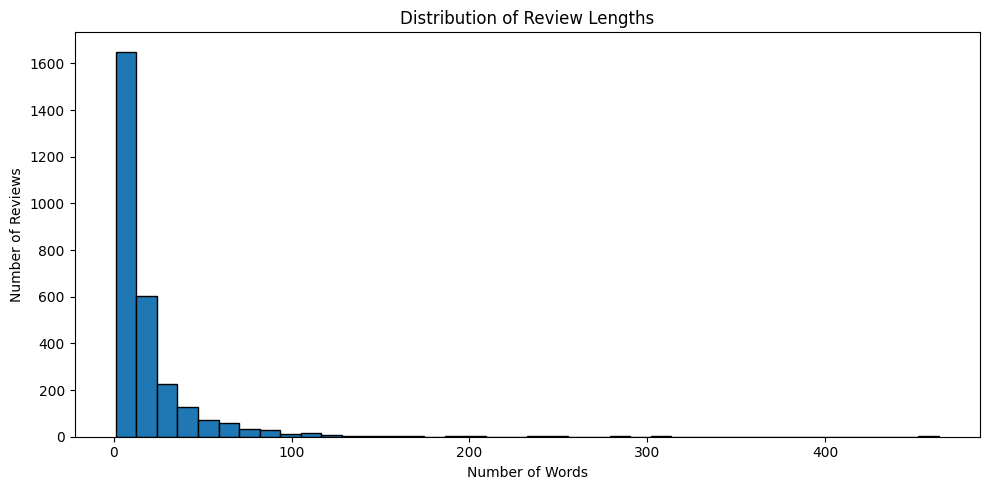

In [37]:
plt.figure(figsize=(10, 5))

plt.hist(df_reviews['n_words'], bins=40, edgecolor='black')

plt.title('Distribution of Review Lengths')
plt.xlabel('Number of Words')
plt.ylabel('Number of Reviews')

plt.tight_layout()
plt.show()

Cell 3 — Compare lengths by sentiment

<Figure size 900x500 with 0 Axes>

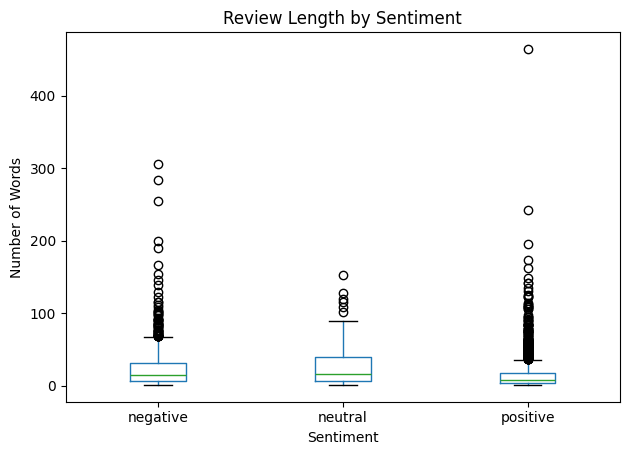

In [38]:
plt.figure(figsize=(9, 5))

df_reviews.boxplot(
    column='n_words',
    by='sentiment',
    grid=False
)

plt.title('Review Length by Sentiment')
plt.suptitle('')
plt.xlabel('Sentiment')
plt.ylabel('Number of Words')

plt.tight_layout()
plt.show()

Cell 4 — Average length by sentiment

In [39]:
display(
    df_reviews.groupby('sentiment')[
        ['n_words', 'n_tokens', 'text_length']
    ].mean().round(2)
)

,n_words,n_tokens,text_length
sentiment,,,
negative,25.43,25.25,140.22
neutral,28.46,28.38,158.01
positive,14.93,15.15,84.83


In [29]:
df_places_clean.to_csv(
    'restaurants_metadata_clean.csv',
    index=False,
    encoding='utf-8-sig'
)

print("Saved successfully!")
print("Final shape:", df_places_clean.shape)

Saved successfully!
Final shape: (684, 31)


**EDA 2: Representative Reviews.**

In [40]:
# Display representative reviews for each sentiment

for sentiment in ['positive', 'neutral', 'negative']:
    print(f"\n{'='*60}")
    print(f"{sentiment.upper()} REVIEWS")
    print('='*60)

    samples = df_reviews[
        (df_reviews['sentiment'] == sentiment) &
        (df_reviews['usable'] == True)
    ]['text_raw'].sample(
        min(3, len(df_reviews[
            (df_reviews['sentiment'] == sentiment) &
            (df_reviews['usable'] == True)
        ])),
        random_state=42
    )

    for i, review in enumerate(samples, 1):
        print(f"{i}. {review}\n")


POSITIVE REVIEWS
1. المطعم كبير مش صغير و نظيف جدا جدا
و فريق العمل كله محترم جدا جدا و مضياف و لذيذ
و الاكل تحفه فعلا انا جربت جمبري بطر فلاي و جمبري مقلي و مكرونه جمبري و سبيط طاجن احمر سبايسي و حتي الارز الساده كان حلو جدا
و هما نزوا ملوخيه و بذنجان و مهلبيه و حلويات شرقيه بعد الاجل كا ضيافه

بشكرهم جدا و بالاخص محمود بوجي هو الي كان مسؤال عن الترابيزه بتاعتنا

2. Service is amazing and the food is such an experience! Their Egyptian-Chinese fusion section of the menu is insane!

3. Food is fabulous


NEUTRAL REVIEWS
1. Being renovated so i didnt see much

2. I ordered pizza from Daje recently. Overall, it was okay- not bad, but it could definitely be improved.

The Margherita pizza was a bit disappointing. The cheese didn’t have much flavour, and the dough felt more like bread dough than proper pizza dough- quite soft and not the typical pizza texture you’d expect. I wish they had used Gouda or high-quality mozzarella instead of what seems to be local Egyptian mozzarella.

On the o

### Representative Reviews by Sentiment

Representative customer reviews were examined from the positive, neutral, and negative sentiment classes.

- **Positive reviews** commonly express satisfaction with food quality, customer service, cleanliness, and staff behavior.
- **Neutral reviews** often contain mixed opinions, moderate satisfaction, or limited information about the restaurant experience.
- **Negative reviews** frequently describe problems related to customer service, food quality, hygiene, and overall customer experience.

The examples also reveal important NLP challenges, including Arabic-English language variation, informal Egyptian Arabic expressions, differences in review length, and mixed sentiment within a single review.

These observations highlight the need for multilingual preprocessing techniques that preserve meaningful expressions and sentiment-related information.

**EDA 3: Arabic NLP characteristics**

In [41]:
# Analyze language distribution

language_counts = df_reviews['language'].value_counts()

display(
    pd.DataFrame({
        'review_count': language_counts,
        'percentage': (
            language_counts / len(df_reviews) * 100
        ).round(2)
    })
)

,review_count,percentage
language,,
ar,1553,54.40
en,1252,43.85
none,20,0.70
mixed,16,0.56
arabizi,9,0.32
other,5,0.18


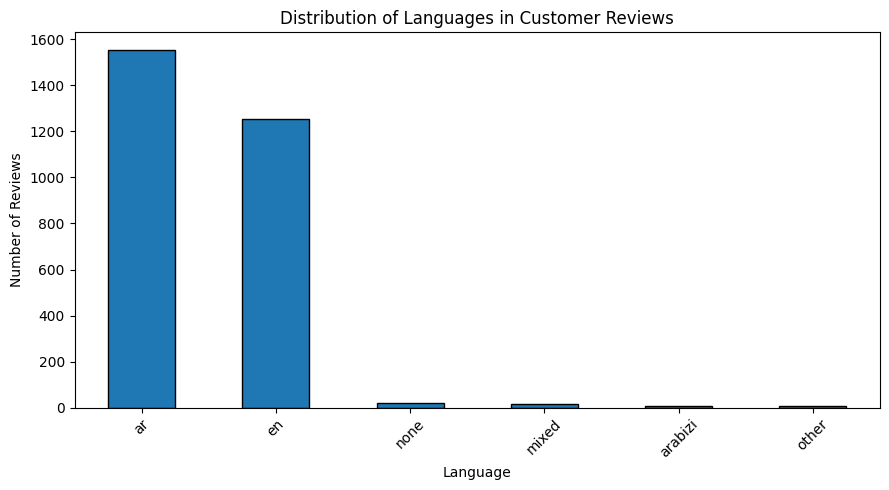

In [42]:
plt.figure(figsize=(9, 5))

language_counts.plot(
    kind='bar',
    edgecolor='black'
)

plt.title('Distribution of Languages in Customer Reviews')
plt.xlabel('Language')
plt.ylabel('Number of Reviews')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Language Distribution and Multilingual Challenges

The dataset contains reviews in multiple language categories:

- Arabic: 1,553 reviews (54.40%).
- English: 1,252 reviews (43.85%).
- None: 20 reviews (0.70%).
- Mixed: 16 reviews (0.56%).
- Arabizi: 9 reviews (0.32%).
- Other: 5 reviews (0.18%).

Arabic and English represent 98.25% of all reviews. Therefore, the preprocessing pipeline must primarily handle Arabic and English text.

Additional challenges include informal Egyptian Arabic, Arabizi (Arabic written using Latin characters and numbers), and code-switching between Arabic and English. These variations can affect tokenization, normalization, and sentiment analysis.

Final check: inspect Arabizi, mixed-language, and elongated text

In [43]:
# Inspect examples of less common language categories

for lang in ['mixed', 'arabizi', 'other']:
    print(f"\n{'='*50}")
    print(f"LANGUAGE: {lang.upper()}")
    print('='*50)

    samples = df_reviews[
        df_reviews['language'] == lang
    ]['text_raw'].head(5)

    for i, review in enumerate(samples, 1):
        print(f"{i}. {review}")

# Check repeated-letter / elongation patterns
print("\nELONGATION ANALYSIS")
print(df_reviews['has_elongation'].value_counts(dropna=False))


LANGUAGE: MIXED
1. سعد كويس جداً وشاطر
He’s the best
2. ال stuff friendly جداً جداً بالذات سعد ، و عملنا اللي نفسنا فيه بجد ، شكراً جداً 🥰🥰🥰
3. كل حاجه ToP
4. بجد اجمل وافل دوقته وما شاء الله الماتريال كلها اوريچنال والسعر كويس جدا مقارنه لباقي الاماكن ...highly recommend Vitwar It has the best waffles and pancakes. 🧇🥞 Thank you
5. ماعندوش عيش في application
يعني تاكل من غير عيش … موضوع غريب جدا

LANGUAGE: ARABIZI
1. To7fa
2. bashe3
3. to7faaaaa 😍😍
4. Gamed❤️
5. To7faaa

LANGUAGE: OTHER
1. 【烤牛肉面】
杭州人，淡口，写给国人：
面是老家做拌面的那种面条，冲着这点来的。面条本身口感可以的。
亚洲风味是比较融合的那种，里面有日本洋葱丝，韩国辣白菜，加上算是中国的面条，就很……emmmm
口味很咸，店家很大方应该放了很多酱油和盐吧，以杭州人的口味我觉得可以要求他们减少到1/3……因为太咸了一边吃一边喝水马上就饱了。
以我平常的实力不至于吃不完一碗的哎。
2. 7월8일 치킨을 오더 해서 접수 된 것까지 확인 했는데 1시간 30분이 지나도 치킨이 오지 않아 연락하니 전화도 안 받고 whatsApp도 답하지 않네요. 참 웃긴 식당 입니다.ㅋㅋ
3. Суши зўракан, маза Кб отрди добрый Кб солишаркан хамма нарсани, гап йоо
4. 好吃！总体是非常正宗的美式汉堡，尤其推荐小食拼盘，种类多而且都很不错
5. Если вам никогда больше не есть тут - добро пожаловать в это заведение. Такого ужаса я не видела ниг

### Additional Multilingual NLP Challenges

Further inspection of mixed, Arabizi, and other-language reviews revealed additional preprocessing challenges.

- **Code-switching:** Some customers combine Arabic and English within the same sentence or review.
- **Arabizi:** Arabic expressions are sometimes written using Latin characters and numbers, such as "To7fa" and "Gamed".
- **Other languages:** A small number of reviews contain Chinese, Korean, and Russian text.
- **Character elongation:** 122 reviews (4.27%) contain repeated characters, which may create inconsistent text representations.

These findings demonstrate why the NLP pipeline should consider language detection, Arabic and English normalization, Arabizi handling, and repeated-character normalization while preserving sentiment-related information.